# Проверки надёжности и воспроизводимости

**Часть 5.** Здесь мы проверяем выводы предыдущих частей на прочность. Семь вопросов:

1. **Сравнение писем.** Какое письмо лучше по трём метрикам с поправкой на множественные сравнения?
2. **Баланс групп.** Подтверждают ли стандартизированные разности средних (SMD) честность деления на группы?
3. **Сегменты.** Опираются ли выводы о различиях эффекта на формальные тесты взаимодействия (а не только на отдельные тесты внутри сегментов), и выдерживают ли они поправки на множественные сравнения?
4. **События в сегментах.** Достаточно ли в сегментах покупок, чтобы доверять оценкам?
5. **Uplift-модели.** Не использует ли сравнение моделей и простого правила одни и те же данные для выбора и для оценки? Насколько устойчивы Qini и экономические выводы к случайному разбиению? Каковы доверительные интервалы выигрыша стратегий?
6. **Python и SQL.** Совпадают ли результаты двух реализаций?
7. **Числа в README.** Совпадают ли ключевые числа с пересчётом на чистом ядре?

Ноутбук самодостаточен: загружает данные и повторяет нужные функции предыдущих частей.

In [5]:
import glob, sys, platform, sqlite3, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import scipy, sklearn, statsmodels
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

# Версии окружения: фиксируем, на чём получены результаты
versions = {
    "python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
    "scipy": scipy.__version__, "statsmodels": statsmodels.__version__, "scikit-learn": sklearn.__version__,
}
print(versions)

paths = glob.glob("/kaggle/input/**/*Hillstrom*.csv", recursive=True) \
     or glob.glob("/kaggle/input/**/*.csv", recursive=True) \
     or glob.glob("../archive/*.csv")
raw = pd.read_csv(paths[0])
print("Файл:", paths[0], raw.shape)

df = raw.copy()
df["newbie_label"] = df["newbie"].map({0: "existing", 1: "new"})
df["recency_bucket"] = pd.cut(df["recency"], [0, 3, 6, 9, 12], labels=["1-3", "4-6", "7-9", "10-12"]).astype(str)
df["buyer_type"] = np.select(
    [(df.mens == 1) & (df.womens == 0), (df.mens == 0) & (df.womens == 1), (df.mens == 1) & (df.womens == 1)],
    ["only_mens", "only_womens", "both"], default="neither")
CONTROL = "No E-Mail"
EMAILS = ["Mens E-Mail", "Womens E-Mail"]
DIMS = ["newbie_label", "channel", "zip_code", "history_segment", "recency_bucket", "buyer_type"]

{'python': '3.13.15', 'pandas': '2.3.3', 'numpy': '2.1.3', 'scipy': '1.16.3', 'statsmodels': '0.15.0', 'scikit-learn': '1.6.1'}
Файл: /kaggle/input/datasets/sumittarya/hillstrom-email-marketing/Kevin_Hillstrom_MineThatData_E-MailAnalytics_DataMiningChallenge_2008.03.20.csv (64000, 12)


## 1. Прямое сравнение писем по трём метрикам

Главный вопрос теста: какое письмо лучше. Сравниваем **все три пары** (мужское против контроля, женское против контроля, мужское против женского) по трём метрикам (конверсия, визиты, траты). Это 9 сравнений, поэтому применяем поправку **Холма** (она мощнее Бонферрони и тоже контролирует вероятность хотя бы одной ложной находки).

Поправка Холма применяется к p-value. Доверительные интервалы в таблицах ниже стандартные 95%, **без поправки на множественные сравнения**: они шире не станут, но одновременное покрытие всех девяти интервалов меньше 95%.

Для долей: z-тест для двух пропорций и интервал Вальда. Для трат (скошенная метрика): t-тест Уэлча и бутстрап-интервал разницы средних.

In [6]:
PAIRS = [("Mens E-Mail", CONTROL), ("Womens E-Mail", CONTROL), ("Mens E-Mail", "Womens E-Mail")]

def compare(a, b, metric, n_boot=2000, seed=0):
    x = df.loc[df.segment == a, metric].to_numpy(float)
    y = df.loc[df.segment == b, metric].to_numpy(float)
    diff = x.mean() - y.mean()
    if metric == "spend":
        p = stats.ttest_ind(x, y, equal_var=False).pvalue
        rng = np.random.default_rng(seed)
        boots = np.array([rng.choice(x, len(x)).mean() - rng.choice(y, len(y)).mean() for _ in range(n_boot)])
        lo, hi = np.percentile(boots, [2.5, 97.5])
    else:
        p = proportions_ztest([x.sum(), y.sum()], [len(x), len(y)])[1]
        se = np.sqrt(x.mean() * (1 - x.mean()) / len(x) + y.mean() * (1 - y.mean()) / len(y))
        lo, hi = diff - 1.96 * se, diff + 1.96 * se
    scale = 100 if metric != "spend" else 1
    return {"метрика": metric, "сравнение": f"{a} - {b}", "разница": diff * scale,
            "CI95 низ": lo * scale, "CI95 верх": hi * scale, "p-value": p}

cmp_all = pd.DataFrame([compare(a, b, m) for m in ["conversion", "visit", "spend"] for a, b in PAIRS])
cmp_all["p (Холм, 9 сравнений)"] = multipletests(cmp_all["p-value"], method="holm")[1]
cmp_all["значимо (Холм)"] = cmp_all["p (Холм, 9 сравнений)"] < 0.05
cmp_all

,метрика,сравнение,разница,CI95 низ,CI95 верх,p-value,"p (Холм, 9 сравнений)",значимо (Холм)
0,conversion,Mens E-Mail - No E-Mail,0.6805,0.5000,0.8610,0.0000,0.0000,True
1,conversion,Womens E-Mail - No E-Mail,0.3111,0.1499,0.4723,0.0002,0.0006,True
2,conversion,Mens E-Mail - Womens E-Mail,0.3694,0.1743,0.5644,0.0002,0.0006,True
3,visit,Mens E-Mail - No E-Mail,7.6590,6.9953,8.3226,0.0000,0.0000,True
4,visit,Womens E-Mail - No E-Mail,4.5233,3.8894,5.1573,0.0000,0.0000,True
5,visit,Mens E-Mail - Womens E-Mail,3.1356,2.4285,3.8428,0.0000,0.0000,True
6,spend,Mens E-Mail - No E-Mail,0.7698,0.4908,1.0539,0.0000,0.0000,True
7,spend,Womens E-Mail - No E-Mail,0.4244,0.1729,0.6736,0.0011,0.0023,True
8,spend,Mens E-Mail - Womens E-Mail,0.3454,0.0204,0.6662,0.0305,0.0305,True


Единицы: для конверсии и визитов разница в процентных пунктах, для трат в долларах на клиента.

Отдельно мужское против женского (3 сравнения, поправка Холма внутри этой тройки):

In [7]:
mv = cmp_all[cmp_all["сравнение"] == "Mens E-Mail - Womens E-Mail"].copy()
mv["p (Холм, 3 метрики)"] = multipletests(mv["p-value"], method="holm")[1]
mv[["метрика", "разница", "CI95 низ", "CI95 верх", "p-value", "p (Холм, 3 метрики)"]].reset_index(drop=True)

,метрика,разница,CI95 низ,CI95 верх,p-value,"p (Холм, 3 метрики)"
0,conversion,0.3694,0.1743,0.5644,0.0002,0.0004
1,visit,3.1356,2.4285,3.8428,0.0000,0.0000
2,spend,0.3454,0.0204,0.6662,0.0305,0.0305


## 2. Баланс групп: SMD и Love plot

В части 1 баланс проверялся p-value (хи-квадрат и ANOVA). Это дополнительная проверка: отсутствие значимости не доказывает баланс, а p-value зависит от размера выборки (при большой выборке он реагирует на ничтожные различия, при малой пропустит заметные). Стандартная метрика баланса это **стандартизированная разность средних (SMD)**: разность средних, делённая на объединённое стандартное отклонение. Правило: |SMD| < 0,1 означает хороший баланс.

Для категориальных признаков считаем SMD по каждой категории (как по доле). Love plot показывает |SMD| для всех признаков и всех трёх пар групп.

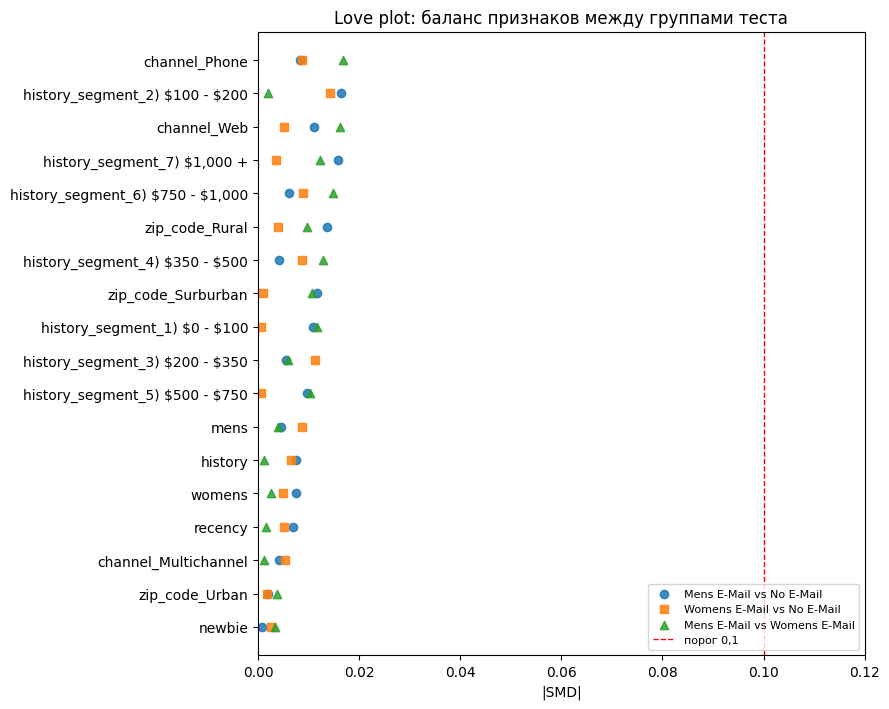

Максимальный |SMD| по парам групп:


Mens E-Mail vs No E-Mail       0.0164
Womens E-Mail vs No E-Mail     0.0143
Mens E-Mail vs Womens E-Mail   0.0169
dtype: float64

In [8]:
import matplotlib.pyplot as plt

X = pd.concat([df[["recency", "history", "newbie", "mens", "womens"]],
               pd.get_dummies(df[["zip_code", "channel", "history_segment"]]).astype(float)], axis=1)

def smd(a, b):
    xa, xb = X[df.segment == a], X[df.segment == b]
    return (xa.mean() - xb.mean()) / np.sqrt((xa.var() + xb.var()) / 2)

smd_table = pd.DataFrame({f"{a} vs {b}": smd(a, b) for a, b in PAIRS})
order = smd_table.abs().max(axis=1).sort_values().index

fig_love, ax = plt.subplots(figsize=(9, 0.3 * len(order) + 1.8))
for col, mk in zip(smd_table.columns, ["o", "s", "^"]):
    ax.scatter(smd_table.loc[order, col].abs(), range(len(order)), marker=mk, label=col, alpha=0.85)
ax.axvline(0.1, color="red", ls="--", lw=1, label="порог 0,1")
ax.set_yticks(range(len(order)))
ax.set_yticklabels([n.replace("$", r"\$") for n in order])
ax.set_xlim(0, 0.12)
ax.set_xlabel("|SMD|")
ax.set_title("Love plot: баланс признаков между группами теста")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

print("Максимальный |SMD| по парам групп:")
smd_table.abs().max().round(4)

Все значения |SMD| далеко ниже порога 0,1 (максимум около 0,017), группы хорошо сбалансированы. SMD согласуется с проверкой p-value из части 1 и служит основной мерой баланса.

## 3. Различается ли эффект между сегментами: формальные тесты

Раньше формальную проверку делали для визитов и конверсии. Здесь добавляем **траты** и показываем, как меняются выводы при разных способах поправки.

Для визитов и конверсии: логистическая регрессия «письмо × сегмент» и критерий отношения правдоподобия. Для трат (непрерывная, скошенная метрика): линейная модель с робастными ошибками HC3 и тест Вальда на все взаимодействия.

Поправка Бенджамини-Хохберга (FDR) применяется двумя способами:
- внутри каждой метрики (12 проверок: 2 письма × 6 признаков);
- сразу ко всем 36 проверкам (самый строгий вариант).

In [9]:
def interaction_p(metric, treat, dim):
    d = df[df.segment.isin([treat, CONTROL])].copy()
    d["treated"] = (d.segment == treat).astype(int)
    if metric in ("visit", "conversion"):
        m0 = smf.logit(f"{metric} ~ treated + C({dim})", d).fit(disp=0)
        m1 = smf.logit(f"{metric} ~ treated * C({dim})", d).fit(disp=0)
        return stats.chi2.sf(2 * (m1.llf - m0.llf), m1.df_model - m0.df_model)
    m1 = smf.ols(f"{metric} ~ treated * C({dim})", d).fit(cov_type="HC3")
    names = [n for n in m1.params.index if n.startswith("treated:")]
    R = np.zeros((len(names), len(m1.params)))
    for i, n in enumerate(names):
        R[i, list(m1.params.index).index(n)] = 1
    return float(m1.wald_test(R, scalar=True).pvalue)

rows = [(m, t, dim, interaction_p(m, t, dim)) for m in ["visit", "conversion", "spend"] for t in EMAILS for dim in DIMS]
inter = pd.DataFrame(rows, columns=["метрика", "письмо", "признак", "p-value"])
inter["q (внутри метрики)"] = inter.groupby("метрика")["p-value"].transform(lambda x: multipletests(x, method="fdr_bh")[1])
inter["q (все 36 проверок)"] = multipletests(inter["p-value"], method="fdr_bh")[1]
inter.sort_values("p-value").head(12).reset_index(drop=True)

,метрика,письмо,признак,p-value,q (внутри метрики),q (все 36 проверок)
0,visit,Womens E-Mail,buyer_type,0.0000,0.0000,0.0000
1,visit,Womens E-Mail,newbie_label,0.0001,0.0003,0.0010
2,visit,Mens E-Mail,newbie_label,0.0005,0.0019,0.0056
3,conversion,Womens E-Mail,newbie_label,0.0013,0.0152,0.0114
4,visit,Womens E-Mail,zip_code,0.0049,0.0148,0.0356
5,spend,Womens E-Mail,newbie_label,0.0177,0.2130,0.0985
6,visit,Womens E-Mail,recency_bucket,0.0191,0.0460,0.0985
7,conversion,Mens E-Mail,newbie_label,0.0268,0.1311,0.1107
8,visit,Mens E-Mail,zip_code,0.0277,0.0553,0.1107
9,conversion,Womens E-Mail,history_segment,0.0328,0.1311,0.1180


In [10]:
# Какие выводы о зависимости эффекта от сегмента выдерживают поправку
inter["значимо внутри метрики"] = inter["q (внутри метрики)"] < 0.05
inter["значимо среди всех 36"] = inter["q (все 36 проверок)"] < 0.05
inter[inter["значимо внутри метрики"] | inter["значимо среди всех 36"]].sort_values("p-value").reset_index(drop=True)

,метрика,письмо,признак,p-value,q (внутри метрики),q (все 36 проверок),значимо внутри метрики,значимо среди всех 36
0,visit,Womens E-Mail,buyer_type,0.0000,0.0000,0.0000,True,True
1,visit,Womens E-Mail,newbie_label,0.0001,0.0003,0.0010,True,True
2,visit,Mens E-Mail,newbie_label,0.0005,0.0019,0.0056,True,True
3,conversion,Womens E-Mail,newbie_label,0.0013,0.0152,0.0114,True,True
4,visit,Womens E-Mail,zip_code,0.0049,0.0148,0.0356,True,True
5,visit,Womens E-Mail,recency_bucket,0.0191,0.0460,0.0985,True,False


### Прямые сравнения эффектов

Фраза «в одном сегменте эффект значим, в другом нет» не доказывает, что эффекты различаются: разница между значимым и незначимым результатом сама может быть незначимой. Поэтому проверяем разницу эффектов напрямую, с доверительным интервалом (линейная модель с робастными ошибками). Это сравнения двух групп, выбранные после просмотра данных, поэтому p-value здесь без поправки.

In [11]:
def contrast(metric, flag_col, flag_name, data):
    d = data.copy()
    d["treated"] = (d.segment == "Womens E-Mail").astype(int)
    m = smf.ols(f"{metric} ~ treated * {flag_col}", d).fit(cov_type="HC3")
    key = f"treated:{flag_col}"
    lo, hi = m.conf_int().loc[key]
    scale = 100 if metric in ("visit", "conversion") else 1
    return {"сравнение": flag_name, "метрика": metric, "разница эффектов": m.params[key] * scale,
            "CI95 низ": lo * scale, "CI95 верх": hi * scale, "p-value": m.pvalues[key]}

wm = df[df.segment.isin(["Womens E-Mail", CONTROL])]
d_bt = wm[wm.buyer_type.isin(["only_womens", "only_mens"])].assign(ow=lambda x: (x.buyer_type == "only_womens").astype(int))
rows = []
for metric in ["visit", "conversion", "spend"]:
    rows.append(contrast(metric, "ow", "женское письмо: покупавшие женское минус покупавшие мужское", d_bt))
    rows.append(contrast(metric, "newbie", "женское письмо: новички минус существующие", wm))
pd.DataFrame(rows)

,сравнение,метрика,разница эффектов,CI95 низ,CI95 верх,p-value
0,женское письмо: покупавшие женское минус покуп...,visit,6.2907,5.0011,7.5803,0.0000
1,женское письмо: новички минус существующие,visit,1.0295,-0.2360,2.2950,0.1108
2,женское письмо: покупавшие женское минус покуп...,conversion,0.4482,0.1207,0.7757,0.0073
3,женское письмо: новички минус существующие,conversion,0.4340,0.1114,0.7567,0.0084
4,женское письмо: покупавшие женское минус покуп...,spend,0.3533,-0.1709,0.8775,0.1865
5,женское письмо: новички минус существующие,spend,0.6183,0.1072,1.1295,0.0177


Доверительные интервалы здесь без поправки на множественные сравнения. Единицы: для визитов и конверсии разница в процентных пунктах, для трат в долларах на клиента.

## 4. Сколько событий в сегментах

Тесты для долей (z-тест, интервал Вальда) опираются на нормальное приближение, которое работает плохо, когда событий мало. Для конверсии события это покупки; для трат тоже (трата бывает только при покупке). Проверяем число покупок в каждой группе каждого сегмента и помечаем сегменты, где хотя бы в одной из двух групп **меньше 20 покупок**. Для них оценки конверсии и трат ненадёжны, даже если они «значимы».

In [12]:
MIN_EVENTS = 20
rows = []
for dim in DIMS:
    for val, d in df.groupby(dim):
        for em in EMAILS:
            e_t = int(d[d.segment == em]["conversion"].sum())
            e_c = int(d[d.segment == CONTROL]["conversion"].sum())
            rows.append({"признак": dim, "сегмент": str(val), "письмо": em,
                         "покупок с письмом": e_t, "покупок в контроле": e_c, "минимум": min(e_t, e_c)})
events = pd.DataFrame(rows)
events["мало событий"] = events["минимум"] < MIN_EVENTS
print(f"Пар сегмент x письмо: {len(events)}; с числом покупок меньше {MIN_EVENTS} в одной из групп: {int(events['мало событий'].sum())}; меньше 10: {int((events['минимум'] < 10).sum())}")
events[events["мало событий"]].sort_values("минимум").reset_index(drop=True)

Пар сегмент x письмо: 44; с числом покупок меньше 20 в одной из групп: 12; меньше 10: 6


,признак,сегмент,письмо,покупок с письмом,покупок в контроле,минимум,мало событий
0,history_segment,"6) $750 - $1,000",Womens E-Mail,8,3,3,True
1,history_segment,"6) $750 - $1,000",Mens E-Mail,16,3,3,True
2,history_segment,"7) $1,000 +",Womens E-Mail,11,6,6,True
3,history_segment,"7) $1,000 +",Mens E-Mail,11,6,6,True
4,history_segment,5) $500 - $750,Mens E-Mail,22,9,9,True
5,history_segment,5) $500 - $750,Womens E-Mail,26,9,9,True
6,recency_bucket,10-12,Womens E-Mail,32,13,13,True
7,recency_bucket,10-12,Mens E-Mail,43,13,13,True
8,recency_bucket,7-9,Mens E-Mail,53,16,16,True
9,recency_bucket,7-9,Womens E-Mail,31,16,16,True


Оценки конверсии и трат для помеченных сегментов нельзя читать как надёжные. Это в основном сегменты с большой историей покупок (от $500) и давностью покупки 10–12 месяцев. Для визитов событий достаточно во всех сегментах.

## 5. Оценка uplift-моделей на отложенной выборке

В части 3 лучшая модель выбиралась по Qini на тех же предсказаниях, на которых затем показывались децили и считалась экономика. Гиперпараметры при этом не подбирались, поэтому утечка небольшая, но формально оценка не независима. Здесь проверяем двумя способами:

- **Устойчивость к разбиению:** повторяем кросс-валидацию с пятью разными seed и смотрим разброс Qini.
- **Отложенная выборка:** 30% клиентов откладываем и не трогаем. Выбор модели и охват (долю клиентов, которым шлём письмо) делаем **только на остальных 70%**, затем один раз оцениваем на отложенных 30%. Повторяем для 10 случайных разбиений, чтобы увидеть разброс. Разбиения пересекаются (каждое берёт 30% из одних и тех же клиентов), поэтому это не десять независимых экспериментов: разброс показывает чувствительность к разбиению и недооценивает реальную неопределённость. Доля «выигрышных» разбиений описательная, это не проверка гипотезы.

In [13]:
NUM = ["recency", "history", "mens", "womens", "newbie"]
CAT = ["zip_code", "channel"]
FEATURES = NUM + CAT
SEED = 42

def make_prep(scale):
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
                              ("num", StandardScaler() if scale else "passthrough", NUM)])

def gb_clf():
    return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150, min_samples_leaf=100, random_state=SEED)

def gb_reg():
    return HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=150, min_samples_leaf=100, random_state=SEED)

def lr_clf():
    return LogisticRegression(max_iter=2000, C=1.0)

def fit_predict(train, test, target, kind):
    if kind in ("t_lr", "t_gb", "t_gb_spend"):
        scale = kind == "t_lr"
        est = {"t_lr": lr_clf, "t_gb": gb_clf, "t_gb_spend": gb_reg}[kind]
        preds = {}
        for t in (0, 1):
            m = make_pipeline(make_prep(scale), est())
            sub = train[train["T"] == t]
            m.fit(sub[FEATURES], sub[target])
            preds[t] = m.predict(test[FEATURES]) if kind == "t_gb_spend" else m.predict_proba(test[FEATURES])[:, 1]
        return preds[1] - preds[0]
    if kind == "ct_lr":
        m = make_pipeline(make_prep(True), lr_clf())
        m.fit(train[FEATURES], (train[target] == train["T"]).astype(int))
        return 2 * m.predict_proba(test[FEATURES])[:, 1] - 1
    raise ValueError(kind)

def oof_scores(d, target, kind, seed, n_splits=5):
    skf = StratifiedKFold(n_splits, shuffle=True, random_state=seed)
    strat = d["T"].astype(str) + "_" + (d[target] > 0).astype(str)
    score = np.zeros(len(d))
    for tr, te in skf.split(d, strat):
        score[te] = fit_predict(d.iloc[tr], d.iloc[te], target, kind)
    return score

def qini_gap(y, t, score):
    order = np.argsort(-score, kind="stable")
    y, t = y[order], t[order]
    cum_t, cum_c = np.cumsum(t), np.cumsum(1 - t)
    q = np.cumsum(y * t) - np.cumsum(y * (1 - t)) * cum_t / np.maximum(cum_c, 1)
    frac = np.arange(1, len(y) + 1) / len(y)
    return np.mean(q - q[-1] * frac)

def profit_at(d, score, cost, grid):
    order = np.argsort(-score, kind="stable")
    x = d.iloc[order].reset_index(drop=True)
    out = []
    for k in grid:
        top = x.iloc[: int(round(k * len(x)))]
        up = top[top["T"] == 1]["spend"].mean() - top[top["T"] == 0]["spend"].mean()
        out.append(1000 * k * (up - cost))
    return np.array(out)

def rule_gain(d, cost):
    up_all = d[d["T"] == 1]["spend"].mean() - d[d["T"] == 0]["spend"].mean()
    m = d["womens"] == 1
    g = d[m]
    up = g[g["T"] == 1]["spend"].mean() - g[g["T"] == 0]["spend"].mean()
    return 1000 * m.mean() * (up - cost) - 1000 * (up_all - cost)

MODELS = {
    "T-learner, логрегрессия": ("t_lr", "visit"),
    "T-learner, бустинг": ("t_gb", "visit"),
    "Преобразование классов, логрегрессия": ("ct_lr", "visit"),
    "T-learner, бустинг по тратам": ("t_gb_spend", "spend"),
}
GRID = np.linspace(0.05, 1.0, 20)
COSTS = [0.05, 0.10, 0.20, 0.30, 0.40]

d_w = df[df.segment.isin(["Womens E-Mail", CONTROL])].reset_index(drop=True).copy()
d_w["T"] = (d_w.segment == "Womens E-Mail").astype(int)
len(d_w)

42693

### 5a. Устойчивость Qini к разбиению кросс-валидации
Qini выражен в числе дополнительных визитов (для трат в долларах). Чем меньше разброс между seed, тем надёжнее оценка.

In [14]:
rows = []
for seed in range(5):
    for name, (kind, target) in MODELS.items():
        s = oof_scores(d_w, target, kind, seed)
        rows.append({"seed": seed, "модель": name,
                     "Qini, визиты": qini_gap(d_w["visit"].to_numpy(float), d_w["T"].to_numpy(), s),
                     "Qini, траты": qini_gap(d_w["spend"].to_numpy(float), d_w["T"].to_numpy(), s)})
stab = pd.DataFrame(rows)
display(stab.groupby("модель")[["Qini, визиты", "Qini, траты"]].agg(["mean", "std", "min", "max"]))

visit_models = stab[stab["модель"] != "T-learner, бустинг по тратам"]
best_by_seed = visit_models.loc[visit_models.groupby("seed")["Qini, визиты"].idxmax(), ["seed", "модель"]]
best_by_seed

Qini, визиты                           Qini, траты                             
                                             mean     std      min      max        mean      std      min        max
модель                                                                                                              
T-learner, бустинг                       142.2165  4.2620 136.9823 148.8495    640.0380 427.8135 -27.8123 1,123.2244
T-learner, бустинг по тратам              13.8696 24.2165  -9.0347  55.1593    849.7339 342.1983 420.3924 1,241.0132
T-learner, логрегрессия                  153.9085  1.7985 150.7818 155.4154    647.5558 207.9673 348.3635   868.9113
Преобразование классов, логрегрессия     156.2787  4.9155 151.3722 163.5531    620.3822 214.8059 416.3992   895.2733

,seed,модель
2,0,"Преобразование классов, логрегрессия"
4,1,"T-learner, логрегрессия"
10,2,"Преобразование классов, логрегрессия"
14,3,"Преобразование классов, логрегрессия"
18,4,"Преобразование классов, логрегрессия"


### 5b. Отложенная выборка

In [15]:
res_q, res_gain = [], []
for rep in range(10):
    strat = d_w["T"].astype(str) + "_" + d_w["visit"].astype(str)
    dev, hold = train_test_split(d_w, test_size=0.3, stratify=strat, random_state=100 + rep)
    dev, hold = dev.reset_index(drop=True), hold.reset_index(drop=True)
    for name, (kind, target) in MODELS.items():
        s_dev = oof_scores(dev, target, kind, SEED)          # выбор охвата только по 70%
        s_hold = fit_predict(dev, hold, target, kind)        # модель обучена на 70%, оценка на 30%
        res_q.append({"разбиение": rep, "модель": name,
                      "Qini, визиты": qini_gap(hold["visit"].to_numpy(float), hold["T"].to_numpy(), s_hold),
                      "Qini, траты": qini_gap(hold["spend"].to_numpy(float), hold["T"].to_numpy(), s_hold)})
        for cost in COSTS:
            k_star = GRID[int(np.argmax(profit_at(dev, s_dev, cost, GRID)))]
            gain = profit_at(hold, s_hold, cost, [k_star])[0] - profit_at(hold, s_hold, cost, [1.0])[0]
            res_gain.append({"разбиение": rep, "модель": name, "стоимость письма": cost, "выигрыш": gain})
    for cost in COSTS:
        res_gain.append({"разбиение": rep, "модель": "Правило: слать, если покупал женское",
                         "стоимость письма": cost, "выигрыш": rule_gain(hold, cost)})
hold_q, hold_gain = pd.DataFrame(res_q), pd.DataFrame(res_gain)
print("Размер отложенной выборки:", len(hold))
display(hold_q.groupby("модель")[["Qini, визиты", "Qini, траты"]].agg(["mean", "std"]))

Размер отложенной выборки: 12808


Qini, визиты         Qini, траты         
                                             mean     std        mean      std
модель                                                                        
T-learner, бустинг                        38.8502  7.8135    455.5747 357.0051
T-learner, бустинг по тратам               9.6491 10.1039    299.6937 781.5052
T-learner, логрегрессия                   50.2203  9.7642    448.9596 371.6816
Преобразование классов, логрегрессия      48.9729  4.4869    445.9083 342.2421

In [16]:
print("Выигрыш относительно рассылки всем на отложенных 30%, $ на 1000 клиентов базы: среднее по 10 разбиениям")
display(hold_gain.pivot_table(index="модель", columns="стоимость письма", values="выигрыш", aggfunc="mean"))
print("Стандартное отклонение по разбиениям")
display(hold_gain.pivot_table(index="модель", columns="стоимость письма", values="выигрыш", aggfunc="std"))
print("Доля разбиений, где таргетинг выиграл у рассылки всем")
display(hold_gain.assign(выиграл=hold_gain["выигрыш"] > 0).pivot_table(index="модель", columns="стоимость письма", values="выиграл", aggfunc="mean"))

Выигрыш относительно рассылки всем на отложенных 30%, $ на 1000 клиентов базы: среднее по 10 разбиениям


стоимость письма,0.0500,0.1000,0.2000,0.3000,0.4000
модель,,,,,
"T-learner, бустинг",-14.6310,-7.5862,4.8139,53.6470,100.6585
"T-learner, бустинг по тратам",-27.7827,-30.6315,-44.4729,-30.1870,30.5156
"T-learner, логрегрессия",-12.4577,-3.1292,-8.9924,25.0415,74.2619
"Правило: слать, если покупал женское",-30.8786,-8.3310,36.7643,81.8595,126.9548
"Преобразование классов, логрегрессия",-33.1170,-30.3670,-29.7193,34.5538,49.5094


Стандартное отклонение по разбиениям


стоимость письма,0.0500,0.1000,0.2000,0.3000,0.4000
модель,,,,,
"T-learner, бустинг",69.2635,65.7789,73.2947,124.4708,127.2697
"T-learner, бустинг по тратам",82.4853,77.8367,144.1129,123.7725,146.2999
"T-learner, логрегрессия",75.5962,78.9887,92.3103,116.5975,119.6582
"Правило: слать, если покупал женское",164.0847,163.9960,163.8192,163.6431,163.4677
"Преобразование классов, логрегрессия",58.3097,54.2507,66.2048,94.1604,147.1034


Доля разбиений, где таргетинг выиграл у рассылки всем


стоимость письма,0.0500,0.1000,0.2000,0.3000,0.4000
модель,,,,,
"T-learner, бустинг",0.1000,0.3000,0.3000,0.5000,0.8000
"T-learner, бустинг по тратам",0.2000,0.2000,0.3000,0.4000,0.7000
"T-learner, логрегрессия",0.1000,0.2000,0.2000,0.4000,0.6000
"Правило: слать, если покупал женское",0.5000,0.5000,0.6000,0.6000,0.8000
"Преобразование классов, логрегрессия",0.0000,0.0000,0.1000,0.5000,0.7000


### 5c. Доверительные интервалы для выигрыша стратегий

В 5b мы видели разброс выигрыша между разбиениями, но это не доверительный интервал. Строим настоящий интервал в два шага.

**Шаг 1. Решения без утечки (вложенная кросс-валидация).** Клиентов делим на 5 частей. Для каждой части модель обучается на остальных четырёх, а охват (доля клиентов, которым шлём письмо) выбирается внутренней кросс-валидацией на тех же четырёх. Так для каждого клиента получаем решение «слать или нет», принятое процедурой, которая его не видела.

**Шаг 2. Оценка выигрыша с интервалом.** Письмо назначалось случайно, поэтому выигрыш любой стратегии можно оценить по данным без модели: для каждого клиента считаем вклад
`psi = траты × (T / p − (1 − T) / (1 − p))`, где T это признак «получил письмо», p доля получивших. Выигрыш стратегии относительно рассылки всем:

> выигрыш на 1000 клиентов = −1000 × среднее по клиентам [ (1 − решение) × (psi − стоимость письма) ]

Интервал получаем бутстрапом по клиентам. Решения «слать или нет» при этом фиксированы (условие на cross-fitted решения): интервал не учитывает неопределённость выбора модели и охвата, поэтому реальная неопределённость больше показанной. Правило «слать, если покупал женское» не зависит от модели, для него решение задано признаком.

In [17]:
COSTS = [0.05, 0.10, 0.20, 0.30, 0.40]
n = len(d_w)
send = {(m, c): np.zeros(n, bool) for m in MODELS for c in COSTS}
skf_outer = StratifiedKFold(5, shuffle=True, random_state=7)
strat_outer = d_w["T"].astype(str) + "_" + d_w["visit"].astype(str)
for tr, te in skf_outer.split(d_w, strat_outer):
    dev = d_w.iloc[tr].reset_index(drop=True)
    test = d_w.iloc[te]
    for name, (kind, target) in MODELS.items():
        s_dev = oof_scores(dev, target, kind, SEED)          # внутренняя кросс-валидация для выбора охвата
        s_te = fit_predict(dev, test, target, kind)          # модель обучена без этой части
        for cost in COSTS:
            k = GRID[int(np.argmax(profit_at(dev, s_dev, cost, GRID)))]
            top = np.argsort(-s_te, kind="stable")[: int(round(k * len(te)))]
            send[(name, cost)][te[top]] = True

strategies = {name: {c: send[(name, c)] for c in COSTS} for name in MODELS}
strategies["Правило: слать, если покупал женское"] = {c: (d_w["womens"] == 1).to_numpy() for c in COSTS}

T_arr = d_w["T"].to_numpy()
Y_arr = d_w["spend"].to_numpy(float)
p1 = T_arr.mean()
psi = Y_arr * (T_arr / p1 - (1 - T_arr) / (1 - p1))

keys = [(name, c) for name in strategies for c in COSTS]
GAIN = np.column_stack([-(1 - strategies[name][c]) * (psi - c) * 1000 for name, c in keys])   # n x число стратегий
est = GAIN.mean(axis=0)
rng = np.random.default_rng(0)
B = 2000
boots = np.empty((B, len(keys)))
for b in range(B):
    boots[b] = GAIN[rng.integers(0, n, n)].mean(axis=0)
lo, hi = np.percentile(boots, [2.5, 97.5], axis=0)

econ = pd.DataFrame({"стратегия": [k[0] for k in keys], "стоимость письма": [k[1] for k in keys],
                     "выигрыш": est, "CI95 низ": lo, "CI95 верх": hi,
                     "доля охвата": [strategies[k[0]][k[1]].mean() for k in keys]})
econ["CI не включает ноль"] = (econ["CI95 низ"] > 0) | (econ["CI95 верх"] < 0)
print("Выигрыш стратегии относительно рассылки всем, $ на 1000 клиентов базы (95% CI):")
fmt = econ.assign(текст=lambda x: x.apply(lambda r: f"{r['выигрыш']:.0f} [{r['CI95 низ']:.0f}; {r['CI95 верх']:.0f}]", axis=1))
display(fmt.pivot_table(index="стратегия", columns="стоимость письма", values="текст", aggfunc="first"))
print("Доля охвата (сколько клиентов получают письмо):")
display(econ.pivot_table(index="стратегия", columns="стоимость письма", values="доля охвата"))
print("Стратегий, у которых интервал выигрыша не включает ноль:", int(econ["CI не включает ноль"].sum()), "из", len(econ))

Выигрыш стратегии относительно рассылки всем, $ на 1000 клиентов базы (95% CI):


стоимость письма,0.0500,0.1000,0.2000,0.3000,0.4000
стратегия,,,,,
"T-learner, бустинг",45 [-32; 126],49 [-28; 130],-14 [-129; 97],-13 [-158; 128],29 [-157; 211]
"T-learner, бустинг по тратам",-69 [-200; 50],-62 [-193; 57],-47 [-187; 87],4 [-159; 162],-41 [-229; 146]
"T-learner, логрегрессия",-27 [-130; 74],-22 [-160; 119],-19 [-160; 130],-23 [-177; 128],2 [-170; 164]
"Правило: слать, если покупал женское",-101 [-284; 82],-78 [-261; 105],-33 [-216; 150],12 [-171; 195],57 [-126; 240]
"Преобразование классов, логрегрессия",-41 [-116; 17],-39 [-114; 19],-37 [-139; 51],-5 [-143; 127],31 [-128; 189]


Доля охвата (сколько клиентов получают письмо):


стоимость письма,0.0500,0.1000,0.2000,0.3000,0.4000
стратегия,,,,,
"T-learner, бустинг",0.9200,0.9200,0.8400,0.7600,0.5200
"T-learner, бустинг по тратам",0.8600,0.8600,0.8000,0.7100,0.5600
"T-learner, логрегрессия",0.9100,0.8500,0.8100,0.7700,0.6500
"Правило: слать, если покупал женское",0.5489,0.5489,0.5489,0.5489,0.5489
"Преобразование классов, логрегрессия",0.9600,0.9600,0.8800,0.7700,0.6200


Стратегий, у которых интервал выигрыша не включает ноль: 0 из 25


Положительное число означает, что стратегия принесла больше, чем рассылка всем (при марже 100%). Если интервал включает ноль, преимущество (или недостаток) стратегии по данным не доказано.

## 6. Совпадают ли Python и SQL
Загружаем данные в SQLite, выполняем запросы из папки `sql/` и сверяем результат с независимым расчётом в pandas.

In [18]:
SQL_SETUP = """
-- Таблица email_campaign загружается из CSV (Hillstrom Email Marketing).
-- Представление customers добавляет понятные сегменты.
DROP VIEW IF EXISTS customers;

CREATE VIEW customers AS
SELECT
    segment,
    recency,
    history,
    history_segment,
    zip_code,
    channel,
    newbie,
    mens,
    womens,
    CASE WHEN newbie = 1 THEN 'new' ELSE 'existing' END AS newbie_label,
    CASE
        WHEN recency <= 3 THEN '1-3'
        WHEN recency <= 6 THEN '4-6'
        WHEN recency <= 9 THEN '7-9'
        ELSE '10-12'
    END AS recency_bucket,
    CASE
        WHEN mens = 1 AND womens = 0 THEN 'only_mens'
        WHEN mens = 0 AND womens = 1 THEN 'only_womens'
        WHEN mens = 1 AND womens = 1 THEN 'both'
        ELSE 'neither'
    END AS buyer_type,
    visit,
    conversion,
    spend
FROM email_campaign;
"""

SQL_SUMMARY = """
-- Итоги теста по группам: размер, визиты, конверсия, траты
SELECT
    segment AS grp,
    COUNT(*) AS customers,
    ROUND(100.0 * AVG(visit), 2) AS visit_rate_pct,
    ROUND(100.0 * AVG(conversion), 3) AS conversion_rate_pct,
    ROUND(AVG(spend), 3) AS spend_per_customer,
    ROUND(SUM(spend) * 1.0 / NULLIF(SUM(conversion), 0), 2) AS avg_order_value
FROM customers
GROUP BY segment
ORDER BY CASE segment WHEN 'No E-Mail' THEN 0 WHEN 'Mens E-Mail' THEN 1 ELSE 2 END;
"""

SQL_FUNNEL = """
-- Воронка по группам: получили письмо -> зашли на сайт -> купили
SELECT
    segment AS grp,
    COUNT(*) AS sent,
    SUM(visit) AS visited,
    SUM(conversion) AS purchased,
    ROUND(100.0 * SUM(visit) / COUNT(*), 2) AS sent_to_visit_pct,
    ROUND(100.0 * SUM(conversion) / NULLIF(SUM(visit), 0), 2) AS visit_to_purchase_pct,
    ROUND(100.0 * SUM(conversion) / COUNT(*), 3) AS sent_to_purchase_pct
FROM customers
GROUP BY segment
ORDER BY CASE segment WHEN 'No E-Mail' THEN 0 WHEN 'Mens E-Mail' THEN 1 ELSE 2 END;
"""

SQL_SEGMENTS = """
-- Эффект каждого письма относительно контроля в каждом сегменте
WITH long AS (
    SELECT 'newbie_label' AS dimension, newbie_label AS value, segment, visit, conversion, spend FROM customers
    UNION ALL
    SELECT 'channel', channel, segment, visit, conversion, spend FROM customers
    UNION ALL
    SELECT 'zip_code', zip_code, segment, visit, conversion, spend FROM customers
    UNION ALL
    SELECT 'history_segment', history_segment, segment, visit, conversion, spend FROM customers
    UNION ALL
    SELECT 'recency_bucket', recency_bucket, segment, visit, conversion, spend FROM customers
    UNION ALL
    SELECT 'buyer_type', buyer_type, segment, visit, conversion, spend FROM customers
),
agg AS (
    SELECT
        dimension, value, segment,
        COUNT(*) AS n,
        AVG(visit) AS visit_rate,
        AVG(conversion) AS conv_rate,
        AVG(spend) AS spend_avg
    FROM long
    GROUP BY dimension, value, segment
)
SELECT
    t.dimension,
    t.value,
    t.segment AS email,
    t.n AS n_email,
    c.n AS n_control,
    ROUND(100.0 * c.visit_rate, 2) AS control_visit_pct,
    ROUND(100.0 * t.visit_rate, 2) AS email_visit_pct,
    ROUND(100.0 * (t.visit_rate - c.visit_rate), 2) AS visit_lift_pp,
    ROUND(100.0 * (t.conv_rate - c.conv_rate), 3) AS conversion_lift_pp,
    ROUND(t.spend_avg - c.spend_avg, 3) AS spend_lift
FROM agg t
JOIN agg c
    ON c.dimension = t.dimension AND c.value = t.value AND c.segment = 'No E-Mail'
WHERE t.segment <> 'No E-Mail'
ORDER BY t.dimension, t.value, t.segment;
"""

SQL_PROFIT = """
-- Вклад в прибыль на 1000 клиентов базы от женского письма
-- Параметры: {{ cost }} – стоимость одного письма, $; {{ margin }} – маржа с продаж (1 = 100% выручки)
-- spend в данных это выручка, поэтому вклад = margin * дополнительные траты - cost
-- Сумма строк = слать всем; строка bought_womens = 1 = правило "слать только покупавшим женское".
WITH base AS (
    SELECT
        womens AS bought_womens,
        COUNT(*) AS n,
        AVG(CASE WHEN segment = 'Womens E-Mail' THEN spend END) AS spend_email,
        AVG(CASE WHEN segment = 'No E-Mail' THEN spend END) AS spend_control
    FROM customers
    WHERE segment IN ('Womens E-Mail', 'No E-Mail')
    GROUP BY womens
)
SELECT
    bought_womens,
    n AS customers,
    ROUND(100.0 * n / (SELECT SUM(n) FROM base), 1) AS share_of_base_pct,
    ROUND(spend_email - spend_control, 3) AS spend_lift,
    ROUND(1000.0 * n / (SELECT SUM(n) FROM base)
          * ({{ margin }} * (spend_email - spend_control) - {{ cost }}), 1) AS profit_per_1000_if_sent
FROM base
ORDER BY bought_womens;
"""

In [19]:
con = sqlite3.connect(":memory:")
raw.to_sql("email_campaign", con, index=False)
con.executescript(SQL_SETUP)

def q(sql_text, **params):
    for k, v in params.items():
        sql_text = sql_text.replace("{{ " + k + " }}", str(v))
    return pd.read_sql(sql_text, con)

checks = []

# сводка по группам
s_sql = q(SQL_SUMMARY).set_index("grp")
s_pd = df.groupby("segment").agg(visit=("visit", "mean"), conv=("conversion", "mean"), spend=("spend", "mean"))
checks.append(("Сводка по группам", bool(
    np.allclose(s_sql["visit_rate_pct"], 100 * s_pd.loc[s_sql.index, "visit"], atol=0.006)
    and np.allclose(s_sql["conversion_rate_pct"], 100 * s_pd.loc[s_sql.index, "conv"], atol=0.0006)
    and np.allclose(s_sql["spend_per_customer"], s_pd.loc[s_sql.index, "spend"], atol=0.0006))))

# воронка
f_sql = q(SQL_FUNNEL).set_index("grp")
f_pd = df.groupby("segment").agg(sent=("visit", "size"), visited=("visit", "sum"), purchased=("conversion", "sum"))
checks.append(("Воронка (число клиентов на каждом шаге)", bool((f_sql[["sent", "visited", "purchased"]].values == f_pd.loc[f_sql.index].values).all())))

# эффекты по сегментам
seg_sql = q(SQL_SEGMENTS)
n_vals, n_bad = 0, 0
for _, r in seg_sql.iterrows():
    d = df[df[r["dimension"]].astype(str) == r["value"]]
    t, c = d[d.segment == r["email"]], d[d.segment == CONTROL]
    exp = {"visit_lift_pp": 100 * (t.visit.mean() - c.visit.mean()),
           "conversion_lift_pp": 100 * (t.conversion.mean() - c.conversion.mean()),
           "spend_lift": t.spend.mean() - c.spend.mean()}
    for k, v in exp.items():
        n_vals += 1
        n_bad += abs(r[k] - v) > (0.006 if k == "visit_lift_pp" else 0.0006)
checks.append((f"Эффекты по сегментам ({n_vals} значений)", n_bad == 0))

# вклад в прибыль
for margin in (1.0, 0.3):
    p = q(SQL_PROFIT, cost=0.10, margin=margin).set_index("bought_womens")["profit_per_1000_if_sent"]
    w = df[df.segment.isin(["Womens E-Mail", CONTROL])]
    ok = True
    for flag in (0, 1):
        g = w[w.womens == flag]
        up = g[g.segment == "Womens E-Mail"].spend.mean() - g[g.segment == CONTROL].spend.mean()
        ok &= abs(p.loc[flag] - 1000 * len(g) / len(w) * (margin * up - 0.10)) < 0.06
    checks.append((f"Вклад в прибыль, маржа {margin:.0%}", bool(ok)))

pd.DataFrame(checks, columns=["что сверяем", "Python == SQL"])

,что сверяем,Python == SQL
0,Сводка по группам,True
1,Воронка (число клиентов на каждом шаге),True
2,Эффекты по сегментам (132 значений),True
3,"Вклад в прибыль, маржа 100%",True
4,"Вклад в прибыль, маржа 30%",True


## 7. Совпадают ли ключевые числа README с пересчётом
Все значения ниже считаются заново из данных и сравниваются с числами, опубликованными в README и выводах.

In [20]:
conv = df.groupby("segment")["conversion"].mean() * 100
vis = df.groupby("segment")["visit"].mean() * 100
wm = df[df.segment.isin(["Womens E-Mail", CONTROL])]
def vis_lift(group):
    g = wm[wm.buyer_type == group]
    return 100 * (g[g.segment == "Womens E-Mail"].visit.mean() - g[g.segment == CONTROL].visit.mean())
g0 = wm[wm.womens == 0]
u_others = g0[g0.segment == "Womens E-Mail"].spend.mean() - g0[g0.segment == CONTROL].spend.mean()

claims = [
    ("Конверсия контроля, %", conv[CONTROL], 0.57, 0.005),
    ("Конверсия женского письма, %", conv["Womens E-Mail"], 0.88, 0.005),
    ("Конверсия мужского письма, %", conv["Mens E-Mail"], 1.25, 0.005),
    ("Рост конверсии женского письма, %", (conv["Womens E-Mail"] / conv[CONTROL] - 1) * 100, 54, 0.5),
    ("Мужское письмо: конверсия выше контроля в раз", conv["Mens E-Mail"] / conv[CONTROL], 2.2, 0.05),
    ("Визиты контроля, %", vis[CONTROL], 10.6, 0.05),
    ("Визиты мужского письма, %", vis["Mens E-Mail"], 18.3, 0.05),
    ("Визиты женского письма, %", vis["Womens E-Mail"], 15.1, 0.05),
    ("Женское письмо, прирост визитов у покупавших женское, п.п.", vis_lift("only_womens"), 7.4, 0.05),
    ("Женское письмо, прирост визитов у покупавших только мужское, п.п.", vis_lift("only_mens"), 1.1, 0.05),
    ("Допстраты группы 'покупали только мужское', $", u_others, 0.28, 0.005),
]
out = pd.DataFrame(claims, columns=["показатель", "пересчёт", "в README", "допуск"])
out["совпадает"] = (out["пересчёт"] - out["в README"]).abs() <= out["допуск"]
out

,показатель,пересчёт,в README,допуск,совпадает
0,"Конверсия контроля, %",0.5726,0.5700,0.0050,True
1,"Конверсия женского письма, %",0.8837,0.8800,0.0050,True
2,"Конверсия мужского письма, %",1.2531,1.2500,0.0050,True
3,"Рост конверсии женского письма, %",54.3313,54.0000,0.5000,True
4,Мужское письмо: конверсия выше контроля в раз,2.1884,2.2000,0.0500,True
5,"Визиты контроля, %",10.6167,10.6000,0.0500,True
6,"Визиты мужского письма, %",18.2757,18.3000,0.0500,True
7,"Визиты женского письма, %",15.1400,15.1000,0.0500,True
8,"Женское письмо, прирост визитов у покупавших ж...",7.3985,7.4000,0.0500,True
9,"Женское письмо, прирост визитов у покупавших т...",1.1078,1.1000,0.0500,True


## Выводы

**1. Прямое сравнение писем.** Мужское письмо лучше женского по конверсии (+0,37 п.п., 95% CI [0,17; 0,56], p по Холму 0,0004) и по визитам (+3,1 п.п. [2,4; 3,8]). По тратам разница лишь пограничная: +$0,35 на клиента [0,02; 0,67], p по Холму 0,031, нижняя граница интервала почти у нуля. Оба письма лучше контроля по всем трём метрикам, и это выдерживает поправку Холма на 9 сравнений (поправка применена к p-value; интервалы без поправки).

**2. Баланс групп.** Максимальный |SMD| равен 0,014–0,017 по трём парам групп при пороге 0,1, деление на группы сбалансировано (Love plot).

**3. Различия эффекта между сегментами.** Формальные тесты взаимодействия подтверждают различия для визитов (тип покупателя и новичок/существующий для женского письма, новичок для мужского, регион для женского). Для конверсии после поправки остаётся только «новичок × женское письмо». Для трат различия не подтверждаются. Разность эффектов между покупавшими женское и покупавшими только мужское для трат не значима ([−0,17; 0,88]).

**4. События в сегментах.** В 12 из 44 пар «сегмент × письмо» меньше 20 покупок в одной из групп, в 6 парах меньше 10 (история покупок от $500, давность 7–12 месяцев, мультиканальные клиенты). Оценки конверсии и трат в этих сегментах ненадёжны, даже если p-value мал.

**5. Uplift-модели.** Ранжирование по визитам устойчиво: Qini на отложенной выборке положителен у всех моделей по визитам. Десять отложенных разбиений пересекаются, поэтому это не независимые эксперименты, а проверка чувствительности. Лучшая модель меняется от seed к seed (в основном преобразование классов), Qini по тратам очень шумный. Результаты бустинга зависят от среды, логистические модели воспроизводятся точно.

**6. Экономика с доверительными интервалами.** Интервалы выигрыша стратегий относительно рассылки всем (вложенная кросс-валидация и оценка IPW) включают ноль во всех 25 комбинациях «стратегия × стоимость письма». Например, правило «покупал женское» даёт +12 [−171; 195] $ на 1000 клиентов при письме за $0,30 и +57 [−126; 240] при $0,40. Интервалы получены бутстрапом по клиентам при зафиксированных решениях и не учитывают неопределённость выбора модели и охвата. Средний выигрыш растёт при дорогом письме, но данные не доказывают, что какой-либо таргетинг выгоднее рассылки всем. При дешёвом письме разумный вариант: слать всем.

**7. Python и SQL, числа README.** Все проверки совпадают: 132 значения сегментных эффектов, вклад в прибыль при марже 100% и 30%, 11 из 11 ключевых чисел README.
